# NLP Project for Disaster Tweet Classification

**Author:** Satish Vonteddu  
**Program:** Data Analytics Internship – NextHikes IT Solutions  
**Batch:** L-110226-W2PM-B15  
**Project Submission:** 15 October 2026

## Project Overview

This project builds an NLP-based binary classification system to determine whether a tweet describes a **real disaster event** or a **non-disaster context**.

The workflow covers:

1. Data exploration and quality checks
2. Text cleaning, tokenization, stopword removal, and lemmatization
3. TF-IDF feature engineering
4. Tweet-level feature engineering
5. Training and comparison of multiple machine-learning models
6. Cross-validation and hyperparameter tuning
7. Confusion matrix, ROC, and Precision–Recall evaluation
8. Overfitting/generalization analysis
9. Model serialization
10. Validation on new tweet text
11. Preparation for Flask/Streamlit deployment

### Final Model

The final selected model is **tuned Multinomial Naive Bayes** with `alpha = 0.5`.

**Final test performance**
- Accuracy: **81.55%**
- Precision: **83.48%**
- Recall: **71.10%**
- F1-score: **76.80%**
- ROC-AUC: **87.27%**
- Average Precision: **87.28%**

### Important Implementation Note

In the original workflow, TF-IDF was fitted before the train/test split. This introduces a small form of feature-information leakage because vocabulary/statistical information from the full dataset is available during feature construction. The reported results are preserved because they are the actual results of this project workflow. For a future production-grade revision, TF-IDF should be fitted only on training data inside a scikit-learn `Pipeline`.

### Deployment

**GitHub repository:** https://github.com/vsatish5621/Disaster-Tweet-Classification  
**Live Streamlit application:** https://disaster-tweet-classification-baylfnxfscsp4xt4dmffxa.streamlit.app/

> **GitHub note:** The dataset CSV and local `.venv` are not included in the public repository. The notebook is included as the complete project analysis and modelling record.

## 1. Environment and Dataset Loading

This section imports the core Python libraries and loads the disaster-tweet dataset.

**Dataset used in this project**
- File: `twitter_disaster.csv`
- Rows: **7,613**
- Columns: **5**
- Target column: `target`
  - `0` = Non-Disaster
  - `1` = Disaster

> **Reproducibility note:** The original project brief describes a 10,000-tweet dataset, but the dataset actually used for this implementation contains 7,613 records. The notebook reports the actual dataset dimensions rather than changing them to match the brief.

The dataset CSV is intentionally not included in the public GitHub repository in this project version. The notebook can still be reviewed as the complete analysis record; to rerun it, place the dataset file in the same working directory or update the path below.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("twitter_disaster.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7613, 5)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


### 1.1 Dataset Structure

We inspect the shape, column names, and data types to understand the dataset before preprocessing.

In [2]:
print("----- DATASET SHAPE -----")
print(df.shape)

print("\n----- COLUMN NAMES -----")
print(df.columns.tolist())

print("\n----- DATA TYPES -----")
print(df.dtypes)

print("\n----- DATASET INFORMATION -----")
df.info()

----- DATASET SHAPE -----
(7613, 5)

----- COLUMN NAMES -----
['id', 'keyword', 'location', 'text', 'target']

----- DATA TYPES -----
id           int64
keyword     object
location    object
text        object
target       int64
dtype: object

----- DATASET INFORMATION -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7613 entries, 0 to 7612
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   id        7613 non-null   int64 
 1   keyword   7552 non-null   object
 2   location  5079 non-null   object
 3   text      7613 non-null   object
 4   target    7613 non-null   int64 
dtypes: int64(2), object(3)
memory usage: 297.5+ KB


### 1.2 Missing-Value Analysis

The dataset is checked for missing values. `keyword` has a small number of missing values, while `location` contains substantially more missing values. These fields are not required for the final text-classification model, so the primary modelling workflow focuses on tweet text and engineered tweet-level features.

In [3]:
print("----- MISSING VALUES -----")

missing = df.isnull().sum()

print(missing)

print("\n----- MISSING VALUE PERCENTAGE -----")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.round(2))

----- MISSING VALUES -----
id             0
keyword       61
location    2534
text           0
target         0
dtype: int64

----- MISSING VALUE PERCENTAGE -----
id           0.00
keyword      0.80
location    33.29
text         0.00
target       0.00
dtype: float64


### 1.3 Target Distribution

The target distribution is examined to understand the balance between disaster and non-disaster tweets before model training.

In [4]:
print("----- TARGET DISTRIBUTION -----")

print(df['target'].value_counts())

print("\n----- TARGET PERCENTAGE -----")

print((df['target'].value_counts(normalize=True) * 100).round(2))

----- TARGET DISTRIBUTION -----
target
0    4342
1    3271
Name: count, dtype: int64

----- TARGET PERCENTAGE -----
target
0    57.03
1    42.97
Name: proportion, dtype: float64


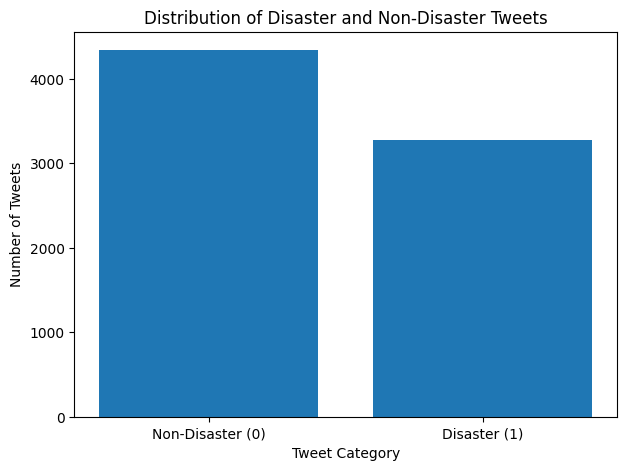

In [5]:
import matplotlib.pyplot as plt

target_counts = df['target'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ['Non-Disaster (0)', 'Disaster (1)'],
    target_counts.values
)

plt.title('Distribution of Disaster and Non-Disaster Tweets')
plt.xlabel('Tweet Category')
plt.ylabel('Number of Tweets')
plt.show()

### 1.5 Keyword Frequency Analysis

The most frequent keywords are reviewed to identify common themes and terms in the dataset.

In [7]:
# Top 20 most frequent keywords

keyword_counts = df['keyword'].value_counts().head(20)

print("Top 20 Most Frequent Keywords:")
display(keyword_counts)

Top 20 Most Frequent Keywords:


,count
keyword,
fatalities,45
deluge,42
armageddon,42
damage,41
body%20bags,41
harm,41
sinking,41
evacuate,40
outbreak,40


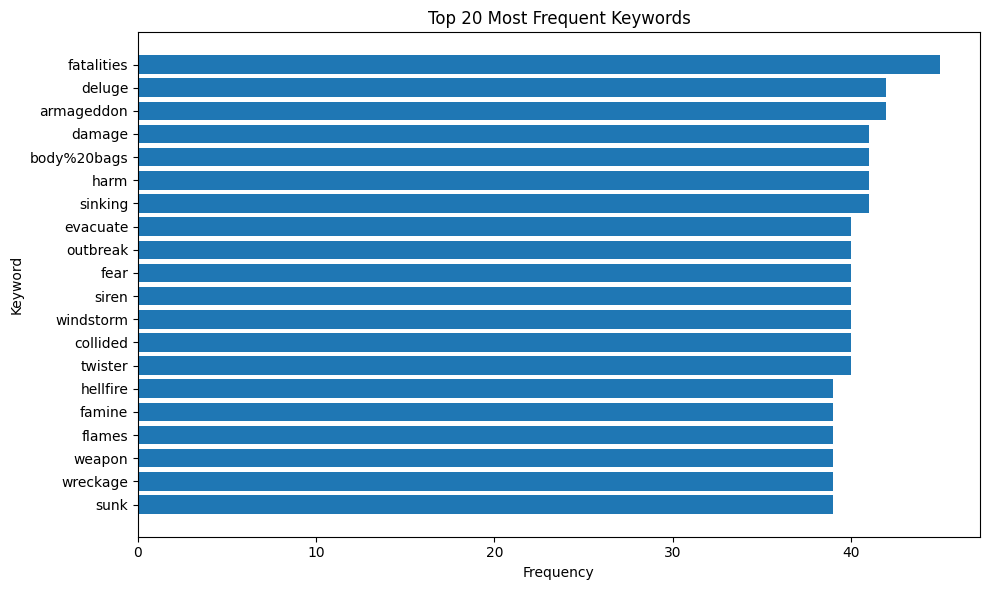

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    keyword_counts.index[::-1],
    keyword_counts.values[::-1]
)

plt.title('Top 20 Most Frequent Keywords')
plt.xlabel('Frequency')
plt.ylabel('Keyword')

plt.tight_layout()
plt.show()

### 1.7 Sample Tweet Inspection

A sample of tweets is displayed to understand the raw text and target labels before cleaning.

In [9]:
# Display sample tweets from the dataset

pd.set_option('display.max_colwidth', 200)

display(
    df[['keyword', 'text', 'target']]
    .sample(10, random_state=42)
)

,keyword,text,target
2644,destruction,So you have a new weapon that can cause un-imaginable destruction.,1
2227,deluge,The f$&amp;@ing things I do for #GISHWHES Just got soaked in a deluge going for pads and tampons. Thx @mishacollins @/@,0
5448,police,DT @georgegalloway: RT @Galloway4Mayor: ÛÏThe CoL police can catch a pickpocket in Liverpool Stree... http://t.co/vXIn1gOq4Q,1
132,aftershock,Aftershock back to school kick off was great. I want to thank everyone for making it possible. What a great night.,0
6845,trauma,in response to trauma Children of Addicts develop a defensive self - one that decreases vulnerability. (3,0
5559,rainstorm,@Calum5SOS you look like you got caught in a rainstorm this is amazing and disgusting at the same time,0
1765,collision,my favorite lady came to our volunteer meeting\nhopefully joining her youth collision and i am excite http://t.co/Ij0wQ490cS,1
1817,crashed,@brianroemmele UX fail of EMV - people want to insert and remove quickly like a gas pump stripe reader. 1 person told me it crashed the POS,1
6810,tragedy,Can't find my ariana grande shirt this is a fucking tragedy,0
4398,hijacking,The Murderous Story Of AmericaÛªs First Hijacking http://t.co/EYUGk6byxr,1


In [10]:
import re

def clean_text(text):
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove newline characters
    text = re.sub(r'\n', ' ', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['cleaned_text'] = df['text'].apply(clean_text)

display(df[['text', 'cleaned_text']].head(10))

,text,cleaned_text
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,our deeds are the reason of this earthquake may allah forgive us all
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,all residents asked to shelter in place are being notified by officers no other evacuation or shelter in place orders are expected
3,"13,000 people receive #wildfires evacuation orders in California",people receive wildfires evacuation orders in california
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,just got sent this photo from ruby alaska as smoke from wildfires pours into a school
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,rockyfire update california hwy closed in both directions due to lake county fire cafire wildfires
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas
7,I'm on top of the hill and I can see a fire in the woods...,i m on top of the hill and i can see a fire in the woods
8,There's an emergency evacuation happening now in the building across the street,there s an emergency evacuation happening now in the building across the street
9,I'm afraid that the tornado is coming to our area...,i m afraid that the tornado is coming to our area


### 2.1 Tokenization

Cleaned tweets are split into individual tokens (words).

In [11]:
# Tokenization

df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())

display(df[['cleaned_text', 'tokens']].head(10))

,cleaned_text,tokens
0,our deeds are the reason of this earthquake may allah forgive us all,"[our, deeds, are, the, reason, of, this, earthquake, may, allah, forgive, us, all]"
1,forest fire near la ronge sask canada,"[forest, fire, near, la, ronge, sask, canada]"
2,all residents asked to shelter in place are being notified by officers no other evacuation or shelter in place orders are expected,"[all, residents, asked, to, shelter, in, place, are, being, notified, by, officers, no, other, evacuation, or, shelter, in, place, orders, are, expected]"
3,people receive wildfires evacuation orders in california,"[people, receive, wildfires, evacuation, orders, in, california]"
4,just got sent this photo from ruby alaska as smoke from wildfires pours into a school,"[just, got, sent, this, photo, from, ruby, alaska, as, smoke, from, wildfires, pours, into, a, school]"
5,rockyfire update california hwy closed in both directions due to lake county fire cafire wildfires,"[rockyfire, update, california, hwy, closed, in, both, directions, due, to, lake, county, fire, cafire, wildfires]"
6,flood disaster heavy rain causes flash flooding of streets in manitou colorado springs areas,"[flood, disaster, heavy, rain, causes, flash, flooding, of, streets, in, manitou, colorado, springs, areas]"
7,i m on top of the hill and i can see a fire in the woods,"[i, m, on, top, of, the, hill, and, i, can, see, a, fire, in, the, woods]"
8,there s an emergency evacuation happening now in the building across the street,"[there, s, an, emergency, evacuation, happening, now, in, the, building, across, the, street]"
9,i m afraid that the tornado is coming to our area,"[i, m, afraid, that, the, tornado, is, coming, to, our, area]"


In [12]:
import nltk

nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [13]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

df['tokens_no_stop'] = df['tokens'].apply(
    lambda tokens: [word for word in tokens if word not in stop_words]
)

display(df[['tokens', 'tokens_no_stop']].head(10))

,tokens,tokens_no_stop
0,"[our, deeds, are, the, reason, of, this, earthquake, may, allah, forgive, us, all]","[deeds, reason, earthquake, may, allah, forgive, us]"
1,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]"
2,"[all, residents, asked, to, shelter, in, place, are, being, notified, by, officers, no, other, evacuation, or, shelter, in, place, orders, are, expected]","[residents, asked, shelter, place, notified, officers, evacuation, shelter, place, orders, expected]"
3,"[people, receive, wildfires, evacuation, orders, in, california]","[people, receive, wildfires, evacuation, orders, california]"
4,"[just, got, sent, this, photo, from, ruby, alaska, as, smoke, from, wildfires, pours, into, a, school]","[got, sent, photo, ruby, alaska, smoke, wildfires, pours, school]"
5,"[rockyfire, update, california, hwy, closed, in, both, directions, due, to, lake, county, fire, cafire, wildfires]","[rockyfire, update, california, hwy, closed, directions, due, lake, county, fire, cafire, wildfires]"
6,"[flood, disaster, heavy, rain, causes, flash, flooding, of, streets, in, manitou, colorado, springs, areas]","[flood, disaster, heavy, rain, causes, flash, flooding, streets, manitou, colorado, springs, areas]"
7,"[i, m, on, top, of, the, hill, and, i, can, see, a, fire, in, the, woods]","[top, hill, see, fire, woods]"
8,"[there, s, an, emergency, evacuation, happening, now, in, the, building, across, the, street]","[emergency, evacuation, happening, building, across, street]"
9,"[i, m, afraid, that, the, tornado, is, coming, to, our, area]","[afraid, tornado, coming, area]"


In [14]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [15]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

df['lemmatized_tokens'] = df['tokens_no_stop'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)

display(df[['tokens_no_stop', 'lemmatized_tokens']].head(10))

,tokens_no_stop,lemmatized_tokens
0,"[deeds, reason, earthquake, may, allah, forgive, us]","[deed, reason, earthquake, may, allah, forgive, u]"
1,"[forest, fire, near, la, ronge, sask, canada]","[forest, fire, near, la, ronge, sask, canada]"
2,"[residents, asked, shelter, place, notified, officers, evacuation, shelter, place, orders, expected]","[resident, asked, shelter, place, notified, officer, evacuation, shelter, place, order, expected]"
3,"[people, receive, wildfires, evacuation, orders, california]","[people, receive, wildfire, evacuation, order, california]"
4,"[got, sent, photo, ruby, alaska, smoke, wildfires, pours, school]","[got, sent, photo, ruby, alaska, smoke, wildfire, pours, school]"
5,"[rockyfire, update, california, hwy, closed, directions, due, lake, county, fire, cafire, wildfires]","[rockyfire, update, california, hwy, closed, direction, due, lake, county, fire, cafire, wildfire]"
6,"[flood, disaster, heavy, rain, causes, flash, flooding, streets, manitou, colorado, springs, areas]","[flood, disaster, heavy, rain, cause, flash, flooding, street, manitou, colorado, spring, area]"
7,"[top, hill, see, fire, woods]","[top, hill, see, fire, wood]"
8,"[emergency, evacuation, happening, building, across, street]","[emergency, evacuation, happening, building, across, street]"
9,"[afraid, tornado, coming, area]","[afraid, tornado, coming, area]"


### 2.4 Final Cleaned Text

The lemmatized tokens are joined back into a single string for feature extraction.

In [16]:
# Combine lemmatized tokens into final cleaned text

df['final_text'] = df['lemmatized_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

display(
    df[['text', 'final_text', 'target']].head(10)
)

,text,final_text,target
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,deed reason earthquake may allah forgive u,1
1,Forest fire near La Ronge Sask. Canada,forest fire near la ronge sask canada,1
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,resident asked shelter place notified officer evacuation shelter place order expected,1
3,"13,000 people receive #wildfires evacuation orders in California",people receive wildfire evacuation order california,1
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,got sent photo ruby alaska smoke wildfire pours school,1
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,rockyfire update california hwy closed direction due lake county fire cafire wildfire,1
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",flood disaster heavy rain cause flash flooding street manitou colorado spring area,1
7,I'm on top of the hill and I can see a fire in the woods...,top hill see fire wood,1
8,There's an emergency evacuation happening now in the building across the street,emergency evacuation happening building across street,1
9,I'm afraid that the tornado is coming to our area...,afraid tornado coming area,1


### 2.5 Additional Tweet-Level Features

Three lightweight features are added alongside TF-IDF:
- **Tweet length**
- **Hashtag presence**
- **Mention presence**

These features provide simple structural information about each tweet.

In [17]:
# Additional tweet-level features

df['tweet_len'] = df['text'].apply(len)

display(
    df[['text', 'tweet_len']].head(10)
)

,text,tweet_len
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,69
1,Forest fire near La Ronge Sask. Canada,38
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,133
3,"13,000 people receive #wildfires evacuation orders in California",65
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,87
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,110
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",95
7,I'm on top of the hill and I can see a fire in the woods...,59
8,There's an emergency evacuation happening now in the building across the street,79
9,I'm afraid that the tornado is coming to our area...,52


### 2.6 Hashtag and Mention Features

Binary indicators identify whether a tweet contains a hashtag or user mention.

In [18]:
# Hashtag and mention features

df['has_hashtag'] = df['text'].apply(
    lambda x: 1 if '#' in x else 0
)

df['has_mention'] = df['text'].apply(
    lambda x: 1 if '@' in x else 0
)

display(
    df[['text', 'has_hashtag', 'has_mention']].head(10)
)

,text,has_hashtag,has_mention
0,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,0
1,Forest fire near La Ronge Sask. Canada,0,0
2,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,0,0
3,"13,000 people receive #wildfires evacuation orders in California",1,0
4,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,0
5,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,1,0
6,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",1,0
7,I'm on top of the hill and I can see a fire in the woods...,0,0
8,There's an emergency evacuation happening now in the building across the street,0,0
9,I'm afraid that the tornado is coming to our area...,0,0


## 3. Feature Engineering

### 3.1 TF-IDF Representation

TF-IDF converts the cleaned tweet text into numerical features. The vocabulary is limited to the top **5,000 features** to control dimensionality.

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer

### 3.2 TF-IDF Matrix

The TF-IDF matrix is created from the final cleaned tweet text.

In [20]:
# Create TF-IDF features

tfidf = TfidfVectorizer(max_features=5000)

X_tfidf = tfidf.fit_transform(df['final_text'])

print("TF-IDF Matrix Shape:", X_tfidf.shape)

TF-IDF Matrix Shape: (7613, 5000)


### 3.3 Combined Feature Matrix

The TF-IDF representation is combined with tweet length, hashtag, and mention features.

In [21]:
from scipy.sparse import hstack

additional_features = df[
    ['tweet_len', 'has_hashtag', 'has_mention']
].values

X = hstack([X_tfidf, additional_features])

print("Final Feature Matrix Shape:", X.shape)

Final Feature Matrix Shape: (7613, 5003)


## 4. Train/Test Split

The data is divided into:
- **80% training data**
- **20% testing data**
- Stratified split to preserve the class distribution
- `random_state=42` for reproducibility

The resulting split is 6,090 training records and 1,523 test records.

In [22]:
from sklearn.model_selection import train_test_split

y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (6090, 5003)
Testing feature shape: (1523, 5003)
Training target shape: (6090,)
Testing target shape: (1523,)


## 5. Candidate Model Training and Evaluation

Several classification algorithms are evaluated to identify a suitable model for disaster-tweet classification.

The candidate models are:
1. Logistic Regression
2. Multinomial Naive Bayes
3. Random Forest
4. XGBoost
5. Neural Network (MLP)

The main evaluation metrics are **Accuracy, Precision, Recall, and F1-score**.

In [23]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

log_reg.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 5.1 Logistic Regression – Test Predictions

In [24]:
# Predictions on test data

y_pred_log = log_reg.predict(X_test)

print("First 20 Predictions:")
print(y_pred_log[:20])

print("\nFirst 20 Actual Values:")
print(y_test.values[:20])

First 20 Predictions:
[0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 1 1 0]

First 20 Actual Values:
[0 0 1 0 0 1 1 1 0 0 0 0 1 1 0 1 1 1 1 0]


### 5.2 Logistic Regression – Evaluation

In [25]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy_log = accuracy_score(y_test, y_pred_log)
precision_log = precision_score(y_test, y_pred_log)
recall_log = recall_score(y_test, y_pred_log)
f1_log = f1_score(y_test, y_pred_log)

print("Logistic Regression Performance")
print("--------------------------------")
print(f"Accuracy : {accuracy_log:.4f}")
print(f"Precision: {precision_log:.4f}")
print(f"Recall   : {recall_log:.4f}")
print(f"F1-Score : {f1_log:.4f}")

Logistic Regression Performance
--------------------------------
Accuracy : 0.8056
Precision: 0.8185
Recall   : 0.7034
F1-Score : 0.7566


### 5.3 Multinomial Naive Bayes

In [26]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


### 5.4 Naive Bayes – Test Predictions

In [27]:
# Naive Bayes predictions

y_pred_nb = nb_model.predict(X_test)

print("First 20 Naive Bayes Predictions:")
print(y_pred_nb[:20])

First 20 Naive Bayes Predictions:
[0 0 1 0 0 0 1 0 0 0 0 0 1 0 1 1 0 1 1 0]


### 5.5 Naive Bayes – Evaluation

In [28]:
# Naive Bayes evaluation

accuracy_nb = accuracy_score(y_test, y_pred_nb)
precision_nb = precision_score(y_test, y_pred_nb)
recall_nb = recall_score(y_test, y_pred_nb)
f1_nb = f1_score(y_test, y_pred_nb)

print("Naive Bayes Performance")
print("-----------------------")
print(f"Accuracy : {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall   : {recall_nb:.4f}")
print(f"F1-Score : {f1_nb:.4f}")

Naive Bayes Performance
-----------------------
Accuracy : 0.8181
Precision: 0.8604
Recall   : 0.6881
F1-Score : 0.7647


### 5.6 Random Forest

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### 5.7 Random Forest – Test Predictions

In [30]:
# Random Forest predictions

y_pred_rf = rf_model.predict(X_test)

print("First 20 Random Forest Predictions:")
print(y_pred_rf[:20])

First 20 Random Forest Predictions:
[1 0 1 0 0 0 0 0 0 0 0 1 1 0 1 1 0 1 1 0]


### 5.8 Random Forest – Evaluation

In [31]:
# Random Forest evaluation

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("-------------------------")
print(f"Accuracy : {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall   : {recall_rf:.4f}")
print(f"F1-Score : {f1_rf:.4f}")

Random Forest Performance
-------------------------
Accuracy : 0.7997
Precision: 0.8299
Recall   : 0.6713
F1-Score : 0.7422


### 5.9 XGBoost

In [32]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


### 5.10 XGBoost – Model Training

In [33]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


### 5.11 XGBoost – Test Predictions

In [34]:
# XGBoost predictions

y_pred_xgb = xgb_model.predict(X_test)

print("First 20 XGBoost Predictions:")
print(y_pred_xgb[:20])

First 20 XGBoost Predictions:
[1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1 1 0]


### 5.12 XGBoost – Evaluation

In [35]:
# XGBoost evaluation

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

print("XGBoost Performance")
print("-------------------")
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1-Score : {f1_xgb:.4f}")

XGBoost Performance
-------------------
Accuracy : 0.7774
Precision: 0.8131
Recall   : 0.6254
F1-Score : 0.7070


### 5.13 Neural Network (MLP)

In [36]:
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation='relu',
    solver='adam',
    max_iter=30,
    early_stopping=True,
    random_state=42
)

nn_model.fit(X_train, y_train)

print("Neural Network model trained successfully.")

Neural Network model trained successfully.


### 5.14 Neural Network – Test Predictions

In [37]:
# Neural Network predictions

y_pred_nn = nn_model.predict(X_test)

print("First 20 Neural Network Predictions:")
print(y_pred_nn[:20])

First 20 Neural Network Predictions:
[0 0 1 0 0 0 0 0 0 0 0 0 1 0 1 1 0 1 1 0]


### 5.15 Neural Network – Evaluation

In [38]:
# Neural Network evaluation

accuracy_nn = accuracy_score(y_test, y_pred_nn)
precision_nn = precision_score(y_test, y_pred_nn)
recall_nn = recall_score(y_test, y_pred_nn)
f1_nn = f1_score(y_test, y_pred_nn)

print("Neural Network Performance")
print("--------------------------")
print(f"Accuracy : {accuracy_nn:.4f}")
print(f"Precision: {precision_nn:.4f}")
print(f"Recall   : {recall_nn:.4f}")
print(f"F1-Score : {f1_nn:.4f}")

Neural Network Performance
--------------------------
Accuracy : 0.8089
Precision: 0.8538
Recall   : 0.6697
F1-Score : 0.7506


In [39]:
import pandas as pd

model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'Random Forest',
        'XGBoost',
        'Neural Network'
    ],
    'Accuracy': [
        accuracy_log,
        accuracy_nb,
        accuracy_rf,
        accuracy_xgb,
        accuracy_nn
    ],
    'Precision': [
        precision_log,
        precision_nb,
        precision_rf,
        precision_xgb,
        precision_nn
    ],
    'Recall': [
        recall_log,
        recall_nb,
        recall_rf,
        recall_xgb,
        recall_nn
    ],
    'F1-Score': [
        f1_log,
        f1_nb,
        f1_rf,
        f1_xgb,
        f1_nn
    ]
})

display(model_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8056,0.8185,0.7034,0.7566
1,Naive Bayes,0.8181,0.8604,0.6881,0.7647
2,Random Forest,0.7997,0.8299,0.6713,0.7422
3,XGBoost,0.7774,0.8131,0.6254,0.7070
4,Neural Network,0.8089,0.8538,0.6697,0.7506


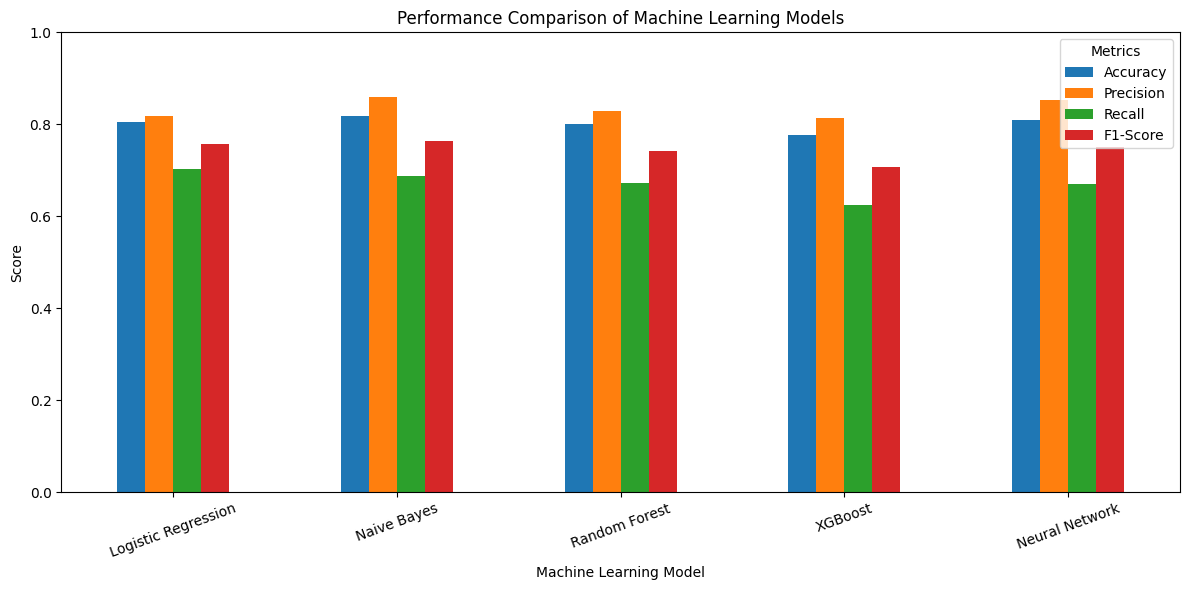

In [40]:
import matplotlib.pyplot as plt

model_results.set_index('Model')[[
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score'
]].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title='Metrics')
plt.tight_layout()
plt.show()

## 7. Cross-Validation

Five-fold stratified cross-validation is used to assess the stability of model performance across multiple train/validation splits.

In [41]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_nb = cross_val_score(
    nb_model,
    X,
    y,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

print("Naive Bayes 5-Fold F1 Scores:")
print(cv_scores_nb)

print(f"\nMean CV F1-Score: {cv_scores_nb.mean():.4f}")
print(f"Standard Deviation: {cv_scores_nb.std():.4f}")

Naive Bayes 5-Fold F1 Scores:
[0.75235647 0.75191816 0.71268335 0.73939394 0.74042553]

Mean CV F1-Score: 0.7394
Standard Deviation: 0.0144


### 7.1 Cross-Validation Results

In [42]:
cv_scores_log = cross_val_score(
    log_reg,
    X,
    y,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

print("Logistic Regression 5-Fold F1 Scores:")
print(cv_scores_log)

print(f"\nMean CV F1-Score: {cv_scores_log.mean():.4f}")
print(f"Standard Deviation: {cv_scores_log.std():.4f}")

Logistic Regression 5-Fold F1 Scores:
[0.75775356 0.75437136 0.73675497 0.75465313 0.75983264]

Mean CV F1-Score: 0.7527
Standard Deviation: 0.0082


## 8. Hyperparameter Tuning – Logistic Regression

Grid search is used to test selected values of `C` and solver options for Logistic Regression.

In [43]:
from sklearn.model_selection import GridSearchCV

log_param_grid = {
    'C': [0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}

log_grid = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid=log_param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

log_grid.fit(X_train, y_train)

print("Best Logistic Regression Parameters:")
print(log_grid.best_params_)

print(f"\nBest Cross-Validation F1-Score: {log_grid.best_score_:.4f}")

Best Logistic Regression Parameters:
{'C': 1, 'solver': 'lbfgs'}

Best Cross-Validation F1-Score: 0.7347


### 8.1 Tuned Logistic Regression Evaluation

In [44]:
# Predictions using the tuned Logistic Regression model

y_pred_log_tuned = log_grid.predict(X_test)

accuracy_log_tuned = accuracy_score(y_test, y_pred_log_tuned)
precision_log_tuned = precision_score(y_test, y_pred_log_tuned)
recall_log_tuned = recall_score(y_test, y_pred_log_tuned)
f1_log_tuned = f1_score(y_test, y_pred_log_tuned)

print("Tuned Logistic Regression Performance")
print("-------------------------------------")
print(f"Accuracy : {accuracy_log_tuned:.4f}")
print(f"Precision: {precision_log_tuned:.4f}")
print(f"Recall   : {recall_log_tuned:.4f}")
print(f"F1-Score : {f1_log_tuned:.4f}")

Tuned Logistic Regression Performance
-------------------------------------
Accuracy : 0.8056
Precision: 0.8185
Recall   : 0.7034
F1-Score : 0.7566


## 9. Hyperparameter Tuning – Multinomial Naive Bayes

Grid search evaluates multiple `alpha` values for Multinomial Naive Bayes. The best configuration is selected using F1-score.

In [45]:
nb_param_grid = {
    'alpha': [0.01, 0.1, 0.5, 1.0, 2.0]
}

nb_grid = GridSearchCV(
    MultinomialNB(),
    param_grid=nb_param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

nb_grid.fit(X_train, y_train)

print("Best Naive Bayes Parameters:")
print(nb_grid.best_params_)

print(f"\nBest Cross-Validation F1-Score: {nb_grid.best_score_:.4f}")

Best Naive Bayes Parameters:
{'alpha': 0.5}

Best Cross-Validation F1-Score: 0.7380


### 9.1 Tuned Naive Bayes Evaluation

The tuned Multinomial Naive Bayes model is selected as the final deployment model based on the evaluation results.

In [46]:
# Predictions using tuned Naive Bayes

y_pred_nb_tuned = nb_grid.predict(X_test)

accuracy_nb_tuned = accuracy_score(y_test, y_pred_nb_tuned)
precision_nb_tuned = precision_score(y_test, y_pred_nb_tuned)
recall_nb_tuned = recall_score(y_test, y_pred_nb_tuned)
f1_nb_tuned = f1_score(y_test, y_pred_nb_tuned)

print("Tuned Naive Bayes Performance")
print("-----------------------------")
print(f"Accuracy : {accuracy_nb_tuned:.4f}")
print(f"Precision: {precision_nb_tuned:.4f}")
print(f"Recall   : {recall_nb_tuned:.4f}")
print(f"F1-Score : {f1_nb_tuned:.4f}")

Tuned Naive Bayes Performance
-----------------------------
Accuracy : 0.8155
Precision: 0.8348
Recall   : 0.7110
F1-Score : 0.7680


## 10. Final Model – Confusion Matrix

The confusion matrix shows the four prediction outcomes:
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)
- True Positive (TP)

This helps explain the types of classification errors made by the final model.

Confusion Matrix:
[[777  92]
 [189 465]]


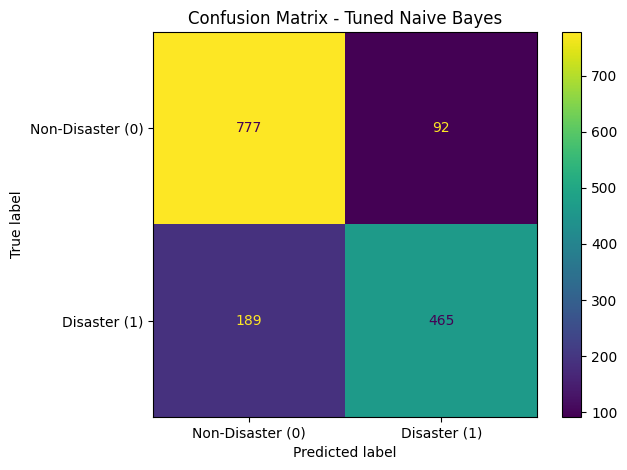

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_nb_tuned)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Disaster (0)', 'Disaster (1)']
)

disp.plot()
plt.title('Confusion Matrix - Tuned Naive Bayes')
plt.tight_layout()
plt.show()

### 10.1 Classification Report

In [48]:
from sklearn.metrics import classification_report

print("Classification Report - Tuned Naive Bayes")
print("------------------------------------------")

print(
    classification_report(
        y_test,
        y_pred_nb_tuned,
        target_names=['Non-Disaster (0)', 'Disaster (1)']
    )
)

Classification Report - Tuned Naive Bayes
------------------------------------------
                  precision    recall  f1-score   support

Non-Disaster (0)       0.80      0.89      0.85       869
    Disaster (1)       0.83      0.71      0.77       654

        accuracy                           0.82      1523
       macro avg       0.82      0.80      0.81      1523
    weighted avg       0.82      0.82      0.81      1523



## 11. ROC Curve and ROC-AUC

The final tuned Naive Bayes model produces probability scores for the Disaster class. The ROC curve evaluates the trade-off between true-positive rate and false-positive rate across classification thresholds.

**Recorded ROC-AUC: 0.8727**

In [49]:
from sklearn.metrics import roc_curve, roc_auc_score

# Probability of the Disaster (1) class
y_prob_nb = nb_grid.predict_proba(X_test)[:, 1]

# ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_nb)

# AUC score
auc_nb = roc_auc_score(y_test, y_prob_nb)

print(f"Naive Bayes ROC-AUC: {auc_nb:.4f}")

Naive Bayes ROC-AUC: 0.8727


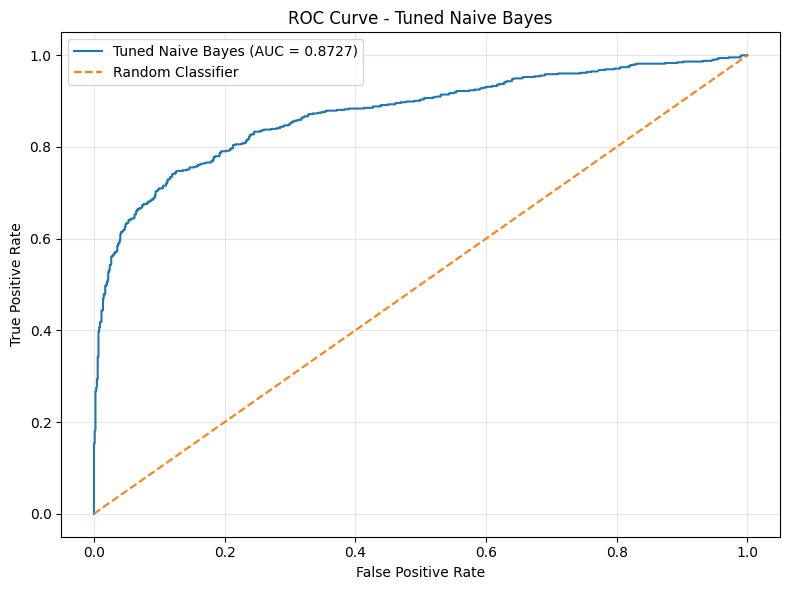

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Tuned Naive Bayes (AUC = {auc_nb:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve - Tuned Naive Bayes')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Precision–Recall Curve

The Precision–Recall curve evaluates the relationship between precision and recall across probability thresholds.

**Recorded Average Precision: 0.8728**

This is particularly useful for classification tasks where the cost of missed positive cases and false alarms both matter.

In [51]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision_curve, recall_curve, _ = precision_recall_curve(
    y_test,
    y_prob_nb
)

ap_nb = average_precision_score(
    y_test,
    y_prob_nb
)

print(f"Naive Bayes Average Precision: {ap_nb:.4f}")

Naive Bayes Average Precision: 0.8728


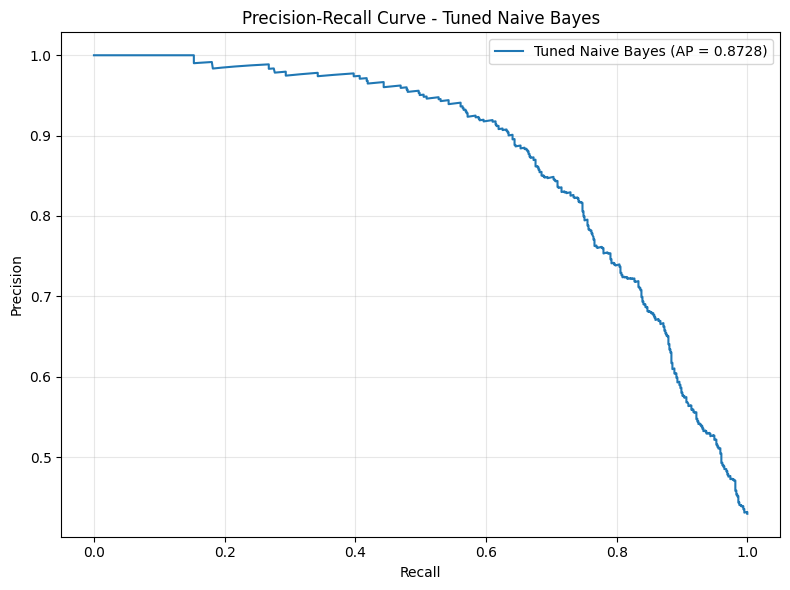

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f'Tuned Naive Bayes (AP = {ap_nb:.4f})'
)

plt.title('Precision-Recall Curve - Tuned Naive Bayes')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 13. Overfitting / Underfitting Check

Training and test F1-scores are compared to identify a potential generalization gap.

For the final tuned Naive Bayes model:
- Training F1: **0.8382**
- Test F1: **0.7680**
- Gap: **0.0702**

The observed gap indicates a moderate training–test difference rather than perfect generalization.

In [53]:
# Overfitting / Underfitting check

y_train_pred_nb = nb_grid.predict(X_train)

train_f1_nb = f1_score(y_train, y_train_pred_nb)
test_f1_nb = f1_score(y_test, y_pred_nb_tuned)

print("Tuned Naive Bayes Fit Check")
print("---------------------------")
print(f"Training F1-Score: {train_f1_nb:.4f}")
print(f"Testing F1-Score : {test_f1_nb:.4f}")
print(f"Difference       : {train_f1_nb - test_f1_nb:.4f}")

Tuned Naive Bayes Fit Check
---------------------------
Training F1-Score: 0.8382
Testing F1-Score : 0.7680
Difference       : 0.0702


## 14. Model Serialization

The selected tuned Multinomial Naive Bayes estimator is serialized with `pickle` for use in the deployment application.

The TF-IDF vectorizer is also saved because the deployment application must transform new tweets using the same learned vocabulary and weighting scheme used by the model.

In [54]:
import pickle

# Save the tuned Naive Bayes model
with open('disaster_tweet_model.pkl', 'wb') as file:
    pickle.dump(nb_grid.best_estimator_, file)

# Save the TF-IDF vectorizer
with open('tfidf_vectorizer.pkl', 'wb') as file:
    pickle.dump(tfidf, file)

print("Model saved as: disaster_tweet_model.pkl")
print("Vectorizer saved as: tfidf_vectorizer.pkl")

Model saved as: disaster_tweet_model.pkl
Vectorizer saved as: tfidf_vectorizer.pkl


In [55]:
import pickle

# Load the saved model
with open('disaster_tweet_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

# Load the saved TF-IDF vectorizer
with open('tfidf_vectorizer.pkl', 'rb') as file:
    loaded_tfidf = pickle.load(file)

print("Saved model loaded successfully.")
print("Saved TF-IDF vectorizer loaded successfully.")

print("\nModel type:", type(loaded_model).__name__)
print("Vectorizer type:", type(loaded_tfidf).__name__)

Saved model loaded successfully.
Saved TF-IDF vectorizer loaded successfully.

Model type: MultinomialNB
Vectorizer type: TfidfVectorizer


### 15.1 Example Prediction

A new disaster-related tweet is passed through the same preprocessing and feature-engineering workflow used by the deployment application.

Example:
> “There is a massive earthquake and buildings are collapsing”

The recorded prediction is **Disaster** with approximately **83.95% probability**.

In [56]:
# Test the reloaded model with a new tweet

new_tweet = "There is a massive earthquake and buildings are collapsing"

# Apply the same preprocessing
cleaned = clean_text(new_tweet)

tokens = cleaned.split()

tokens_no_stop = [
    word for word in tokens
    if word not in stop_words
]

lemmatized = [
    lemmatizer.lemmatize(word)
    for word in tokens_no_stop
]

final_text = ' '.join(lemmatized)

# Create TF-IDF features
tweet_tfidf = loaded_tfidf.transform([final_text])

# Create additional features
tweet_len = len(new_tweet)
has_hashtag = 1 if '#' in new_tweet else 0
has_mention = 1 if '@' in new_tweet else 0

additional_features = [[
    tweet_len,
    has_hashtag,
    has_mention
]]

# Combine features
tweet_features = hstack([
    tweet_tfidf,
    additional_features
])

# Prediction
prediction = loaded_model.predict(tweet_features)[0]
probability = loaded_model.predict_proba(tweet_features)[0][1]

print("New Tweet:")
print(new_tweet)

print("\nProcessed Text:")
print(final_text)

print("\nPrediction:")
print("Disaster" if prediction == 1 else "Non-Disaster")

print(f"Disaster Probability: {probability:.4f}")

New Tweet:
There is a massive earthquake and buildings are collapsing

Processed Text:
massive earthquake building collapsing

Prediction:
Disaster
Disaster Probability: 0.8395


## 16. Deployment Artifacts

The notebook prepares the model and TF-IDF files required by the Flask deployment workflow.

The public project repository contains the serialized model, vectorizer, Flask application, HTML template, and requirements file. The Streamlit deployment uses the same trained model artifacts.

In [57]:
import zipfile
from google.colab import files

# Create a ZIP file containing both deployment files
with zipfile.ZipFile(
    'disaster_tweet_model_files.zip',
    'w'
) as zip_file:

    zip_file.write('disaster_tweet_model.pkl')
    zip_file.write('tfidf_vectorizer.pkl')

print("ZIP file created successfully.")

# Download the ZIP file
files.download('disaster_tweet_model_files.zip')

ZIP file created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Exploratory Word-Frequency Analysis

The cleaned corpus is summarized using word frequencies to identify common terms across the tweets.

In [1]:
from collections import Counter
import matplotlib.pyplot as plt

# Combine all final preprocessed words
all_words = ' '.join(df['final_text']).split()

# Count word frequency
word_counts = Counter(all_words)

# Get top 20 words
top_words = word_counts.most_common(20)

# Display top 20 words
print("Top 20 Most Frequent Words:")
for word, count in top_words:
    print(f"{word}: {count}")

# Plot
words = [x[0] for x in top_words]
counts = [x[1] for x in top_words]

plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.xticks(rotation=45, ha='right')
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined

## 18. Reusable Preprocessing Logic

This section reconstructs the preprocessing logic so that the same text-cleaning approach can be used when testing or deploying the model on new tweet text.

In [3]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Load dataset
df = pd.read_csv('/content/twitter_disaster.csv')

# Download required NLP resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# Text cleaning
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\n', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Preprocessing
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

df['cleaned_text'] = df['text'].apply(clean_text)
df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())

df['tokens_no_stop'] = df['tokens'].apply(
    lambda tokens: [word for word in tokens if word not in stop_words]
)

df['lemmatized_tokens'] = df['tokens_no_stop'].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)

df['final_text'] = df['lemmatized_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

print("Dataset restored successfully!")
print("Shape:", df.shape)
print(df[['text', 'final_text']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Dataset restored successfully!
Shape: (7613, 10)
                                                text  \
0  Our Deeds are the Reason of this #earthquake M...   
1             Forest fire near La Ronge Sask. Canada   
2  All residents asked to 'shelter in place' are ...   
3  13,000 people receive #wildfires evacuation or...   
4  Just got sent this photo from Ruby #Alaska as ...   

                                          final_text  
0         deed reason earthquake may allah forgive u  
1              forest fire near la ronge sask canada  
2  resident asked shelter place notified officer ...  
3  people receive wildfire evacuation order calif...  
4  got sent photo ruby alaska smoke wildfire pour...  


Top 20 Most Frequent Words:
fire: 356
like: 350
amp: 344
u: 265
get: 255
new: 228
via: 220
news: 213
one: 209
people: 201
time: 181
year: 178
video: 175
disaster: 162
emergency: 159
body: 155
day: 151
home: 144
police: 143
building: 141


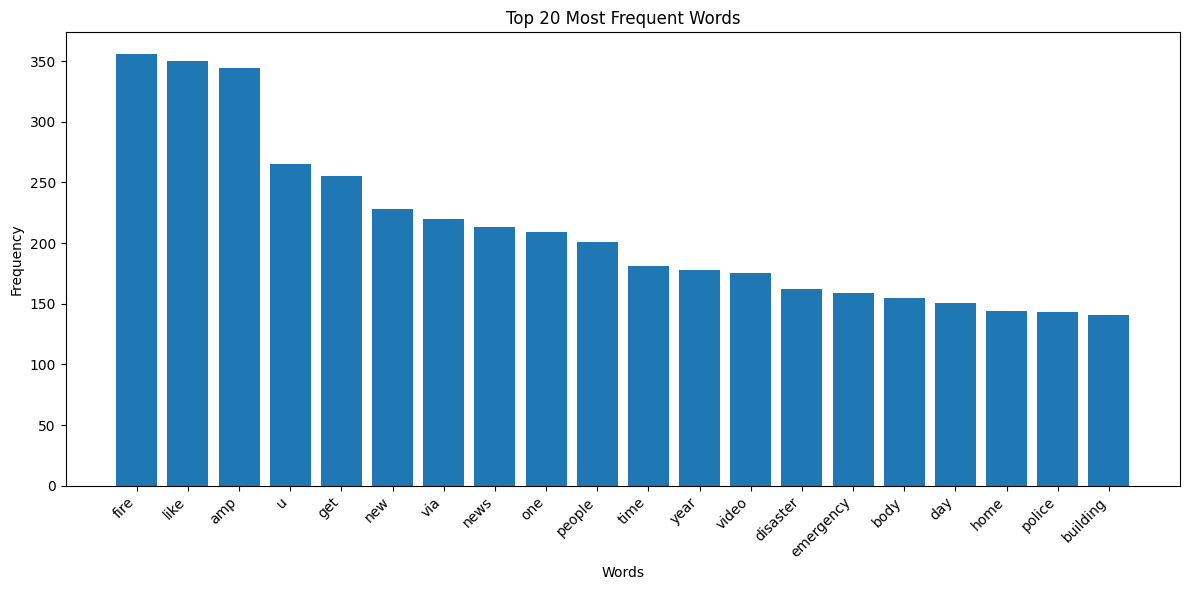

In [4]:
from collections import Counter
import matplotlib.pyplot as plt

# Combine all preprocessed words
all_words = ' '.join(df['final_text']).split()

# Count word frequency
word_counts = Counter(all_words)

# Get top 20 words
top_words = word_counts.most_common(20)

print("Top 20 Most Frequent Words:")
for word, count in top_words:
    print(f"{word}: {count}")

# Prepare data for plot
words = [x[0] for x in top_words]
counts = [x[1] for x in top_words]

# Plot top 20 words
plt.figure(figsize=(12, 6))
plt.bar(words, counts)
plt.xticks(rotation=45, ha='right')
plt.title("Top 20 Most Frequent Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 19. Exploratory Sentiment Analysis

VADER sentiment analysis is included as an **exploratory feature/analysis**, not as part of the final deployed model.

The observed sentiment categories are:
- Negative: 3,708
- Neutral: 2,012
- Positive: 1,893

The final deployed classifier remains the tuned Multinomial Naive Bayes model using TF-IDF plus tweet-level features.

In [5]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

# Download VADER sentiment lexicon
nltk.download('vader_lexicon')

# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

# Calculate sentiment scores
df['sentiment_score'] = df['text'].apply(
    lambda x: sia.polarity_scores(str(x))['compound']
)

# Create sentiment category
df['sentiment'] = df['sentiment_score'].apply(
    lambda x: 'Positive' if x > 0.05
    else ('Negative' if x < -0.05 else 'Neutral')
)

# Display sentiment distribution
print("Sentiment Distribution:")
print(df['sentiment'].value_counts())

# Display examples
print("\nSample Sentiment Results:")
print(df[['text', 'sentiment_score', 'sentiment']].head(10))

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


Sentiment Distribution:
sentiment
Negative    3708
Neutral     2012
Positive    1893
Name: count, dtype: int64

Sample Sentiment Results:
                                                text  sentiment_score  \
0  Our Deeds are the Reason of this #earthquake M...           0.2732   
1             Forest fire near La Ronge Sask. Canada          -0.3400   
2  All residents asked to 'shelter in place' are ...          -0.2960   
3  13,000 people receive #wildfires evacuation or...           0.0000   
4  Just got sent this photo from Ruby #Alaska as ...           0.0000   
5  #RockyFire Update => California Hwy. 20 closed...          -0.3400   
6  #flood #disaster Heavy rain causes flash flood...           0.0000   
7  I'm on top of the hill and I can see a fire in...          -0.1531   
8  There's an emergency evacuation happening now ...          -0.3818   
9  I'm afraid that the tornado is coming to our a...           0.0000   

  sentiment  
0  Positive  
1  Negative  
2  Negative  
3 

# 20. Final Project Summary

## Key Findings

The project successfully developed an end-to-end disaster tweet classification workflow. Five candidate models were evaluated, followed by cross-validation and hyperparameter tuning. The tuned Multinomial Naive Bayes model achieved the strongest final balance for this implementation and was selected for deployment.

### Final Model Metrics

| Metric | Result |
|---|---:|
| Accuracy | 81.55% |
| Precision | 83.48% |
| Recall | 71.10% |
| F1-score | 76.80% |
| ROC-AUC | 87.27% |
| Average Precision | 87.28% |

### Confusion Matrix

- True Negatives: **777**
- False Positives: **92**
- False Negatives: **189**
- True Positives: **465**

### Deployment Flow

**User tweet → Text preprocessing → TF-IDF transformation → Tweet-level features → Tuned Naive Bayes → Disaster/Non-Disaster prediction + probability**

### Repository Contents

The GitHub repository contains the deployable application and supporting files, including:
- `disaster_classifier_app.py`
- `app.py`
- `Templates/index.html`
- `disaster_tweet_model.pkl`
- `tfidf_vectorizer.pkl`
- `requirements.txt`
- `README.md`
- this project notebook

### Reproducibility

To reproduce the notebook from scratch, provide the original `twitter_disaster.csv` dataset in the notebook's working directory and install the required Python packages. The notebook was originally developed/executed in a Google Colab-style environment, while the final application was also deployed through Streamlit Community Cloud.

### Conclusion

This project demonstrates a complete NLP machine-learning lifecycle: **data preparation → feature engineering → model comparison → tuning → evaluation → serialization → deployment**. The solution provides a practical baseline for automatically identifying disaster-related tweets and can be improved further using leakage-free pipelines, richer NLP representations, and larger/diverse training data.